In [1]:
import pandas as pd
import matplotlib.pyplot as plt

route = pd.read_csv("../data/Route_Details_Cleaned.csv")

print("Route dataset loaded successfully!")
print("Total rows and columns:", route.shape)

display(route.head())

Route dataset loaded successfully!
Total rows and columns: (60, 6)


,Route_ID,Origin_City,Destination_City,Distance_KM,Estimated_Travel_Hours,Transport_Cost_Per_KM
0,R001,Hyderabad,Vijayawada,275,6.2,22.47
1,R002,Hyderabad,Tirupati,560,11.3,22.28
2,R003,Hyderabad,Chennai,625,15.9,19.67
3,R004,Hyderabad,Bengaluru,570,13.4,23.21
4,R005,Hyderabad,Nagpur,500,13.7,29.60


In [2]:
print("ROUTE STATISTICAL SUMMARY")

display(
    route[
        ["Distance_KM", "Estimated_Travel_Hours",
         "Transport_Cost_Per_KM"]
    ].describe().round(2)
)

ROUTE STATISTICAL SUMMARY


,Distance_KM,Estimated_Travel_Hours,Transport_Cost_Per_KM
count,60.00,60.00,60.00
mean,700.17,16.52,25.04
std,347.98,7.10,4.53
min,135.00,4.70,18.03
25%,500.00,12.40,20.48
50%,655.00,16.15,23.86
75%,900.00,20.20,29.54
max,1670.00,34.60,30.69


In [3]:
route["Route_Name"] = (
    route["Origin_City"] + " to " + route["Destination_City"]
)

print("TOP 10 LONGEST ROUTES")

display(
    route.sort_values(
        by="Distance_KM",
        ascending=False
    )[["Route_Name", "Distance_KM",
       "Estimated_Travel_Hours"]].head(10)
)

print("TOP 10 SHORTEST ROUTES")

display(
    route.sort_values(
        by="Distance_KM",
        ascending=True
    )[["Route_Name", "Distance_KM",
       "Estimated_Travel_Hours"]].head(10)
)

TOP 10 LONGEST ROUTES


,Route_Name,Distance_KM,Estimated_Travel_Hours
14,Chennai to Kolkata,1670,32.8
44,Kolkata to Chennai,1670,32.8
54,Kolkata to Delhi,1530,34.6
24,Delhi to Kolkata,1530,34.6
8,Vijayawada to Kolkata,1100,25.5
38,Kolkata to Vijayawada,1100,25.5
55,Nagpur to Delhi,1050,23.3
25,Delhi to Nagpur,1050,23.3
16,Bengaluru to Mumbai,980,24.0
46,Mumbai to Bengaluru,980,24.0


TOP 10 SHORTEST ROUTES


,Route_Name,Distance_KM,Estimated_Travel_Hours
9,Tirupati to Chennai,135,4.7
39,Chennai to Tirupati,135,4.7
48,Pune to Mumbai,150,6.2
18,Mumbai to Pune,150,6.2
10,Tirupati to Bengaluru,250,7.7
40,Bengaluru to Tirupati,250,7.7
30,Vijayawada to Hyderabad,275,6.2
0,Hyderabad to Vijayawada,275,6.2
42,Bengaluru to Chennai,350,8.7
12,Chennai to Bengaluru,350,8.7


In [4]:
route["Estimated_Route_Cost"] = (
    route["Distance_KM"] *
    route["Transport_Cost_Per_KM"]
)

print("ROUTE-WISE ESTIMATED TRANSPORT COST")

display(
    route[
        ["Route_Name", "Distance_KM",
         "Transport_Cost_Per_KM", "Estimated_Route_Cost"]
    ].sort_values(
        by="Estimated_Route_Cost",
        ascending=False
    ).head(10).round(2)
)

ROUTE-WISE ESTIMATED TRANSPORT COST


,Route_Name,Distance_KM,Transport_Cost_Per_KM,Estimated_Route_Cost
14,Chennai to Kolkata,1670,29.87,49882.9
44,Kolkata to Chennai,1670,29.87,49882.9
54,Kolkata to Delhi,1530,28.31,43314.3
24,Delhi to Kolkata,1530,28.31,43314.3
25,Delhi to Nagpur,1050,28.92,30366.0
55,Nagpur to Delhi,1050,28.92,30366.0
53,Ahmedabad to Delhi,950,30.42,28899.0
23,Delhi to Ahmedabad,950,30.42,28899.0
58,Vijayawada to Kochi,900,30.50,27450.0
28,Kochi to Vijayawada,900,30.50,27450.0


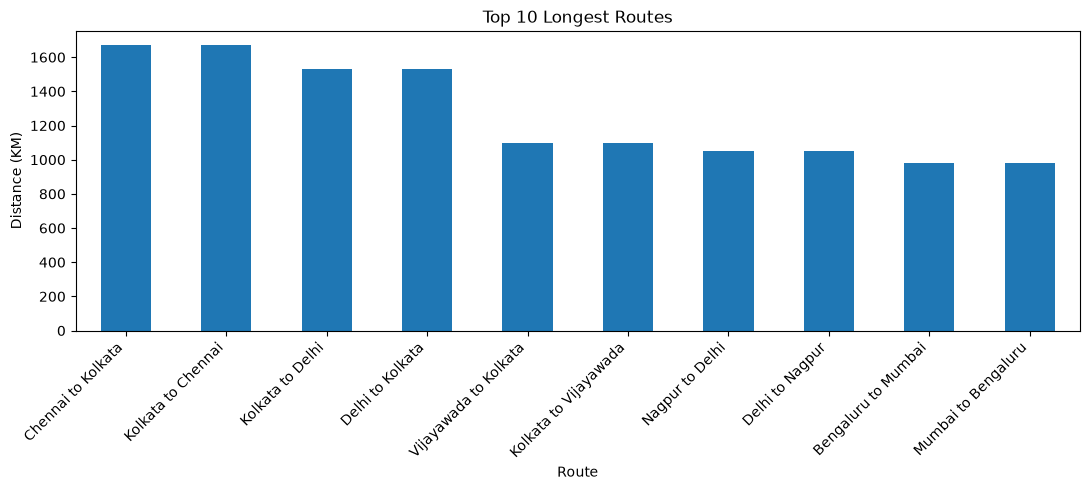

In [5]:
top_routes = route.sort_values(
    by="Distance_KM", ascending=False
).head(10)

top_routes.plot(
    x="Route_Name",
    y="Distance_KM",
    kind="bar",
    figsize=(11, 5),
    legend=False
)

plt.title("Top 10 Longest Routes")
plt.xlabel("Route")
plt.ylabel("Distance (KM)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

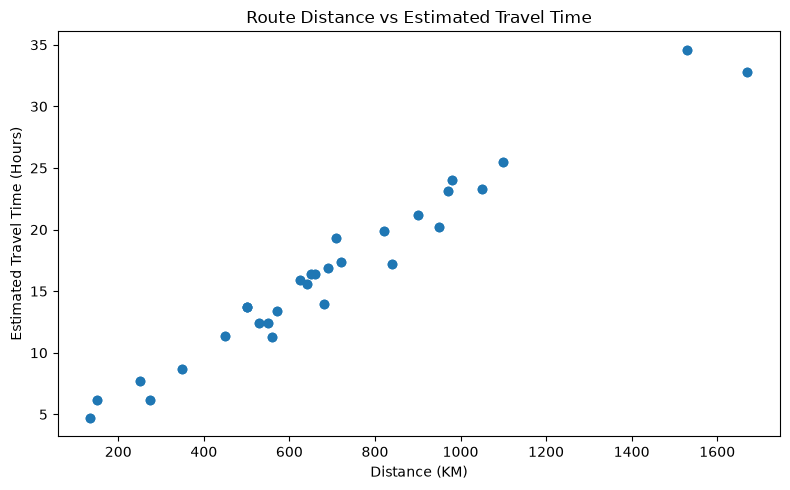

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    route["Distance_KM"],
    route["Estimated_Travel_Hours"]
)

plt.title("Route Distance vs Estimated Travel Time")
plt.xlabel("Distance (KM)")
plt.ylabel("Estimated Travel Time (Hours)")

plt.tight_layout()
plt.show()

In [7]:
route.to_csv("../outputs/route_analysis_data.csv", index=False)

route[[
    "Route_Name",
    "Distance_KM",
    "Estimated_Travel_Hours",
    "Transport_Cost_Per_KM",
    "Estimated_Route_Cost"
]].to_csv("../outputs/route_findings.csv", index=False)

print("Route analysis files saved successfully!")

Route analysis files saved successfully!
